# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab (обраний спосіб)
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data (1).csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [3]:
# Варіант 2. Завантаження датасету через KaggleHub — не використовується (обрано варіант 1)
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# Перші рядки, структура та розмір датасету
display(df.head())
print()
df.info()
print("\nРозмір датасету (рядки, стовпці):", df.shape)

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету (рядки, стовпці): (2338, 14)


In [5]:
# Кількість пропусків і дублікатів
print("Пропущені значення у стовпцях:")
print(df.isnull().sum())
print("\nЗагальна кількість пропусків:", df.isnull().sum().sum())
print("Кількість повних дублікатів:", df.duplicated().sum())

Пропущені значення у стовпцях:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Загальна кількість пропусків: 0
Кількість повних дублікатів: 0


In [6]:
# Описова статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
Датасет містить 2 338 спостережень і 14 стовпців: 13 числових ознак (характеристики магічних інгредієнтів, тип float64) і цільову змінну `Cured` (int64). Пропущених значень і повних дублікатів немає, тому додаткове очищення не потрібне. Усі ознаки мають схожий діапазон — від 1,0 до 33–45, а середні значення лежать в межах 10,9–16,9; проте стандартні відхилення різні (від 7,0 у `Minotaur Horn` до 9,6 у `Troll Hair`), тому перед логістичною регресією доцільна стандартизація. Медіани більшості ознак трохи менші за середні, що вказує на невелику правосторонню асиметрію. Середнє значення `Cured` ≈ 0,497, тобто класи приблизно рівні.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# Ознаки та цільова змінна
X = df.drop(columns='Cured')
y = df['Cured']

# Поділ 80% / 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (1870, 13) | X_test: (468, 13)
y_train: (1870,) | y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Кількість спостережень кожного класу в y_train
print(y_train.value_counts())
print("\nЧастка класів, %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Cured
0    946
1    924
Name: count, dtype: int64

Частка класів, %:
Cured
0    50.59
1    49.41
Name: proportion, dtype: float64


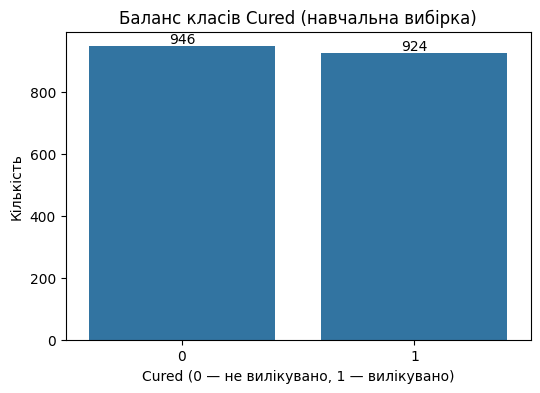

In [9]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y_train, color='tab:blue')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Баланс класів Cured (навчальна вибірка)')
plt.xlabel('Cured (0 — не вилікувано, 1 — вилікувано)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
У навчальній вибірці 946 спостережень класу 0 (50,59 %) і 924 — класу 1 (49,41 %), тобто класи **практично збалансовані**. Тому Accuracy тут є коректною метрикою, і балансування (SMOTE, ваги класів) не потрібне. Якби класи були незбалансовані, модель могла б отримати високу Accuracy, просто передбачаючи переважний клас, і тоді треба було б орієнтуватися на recall, precision та F1.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

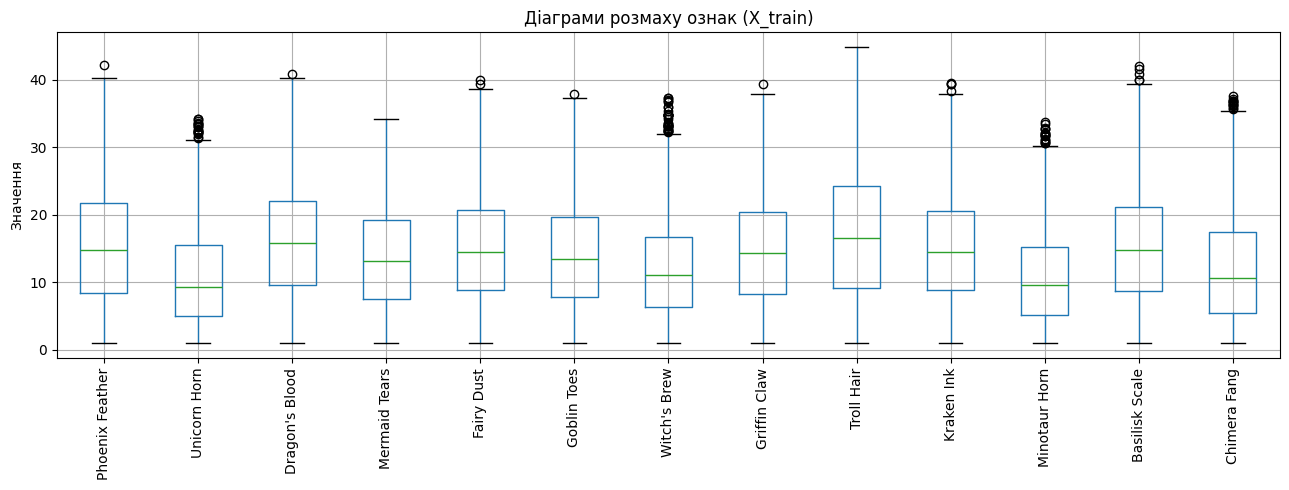

In [10]:
# Діаграми розмаху для ознак навчальної вибірки
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху ознак (X_train)')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [11]:
# Межі за правилом 1.5*IQR (лише за навчальною вибіркою)
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers_count = ((X_train < lower) | (X_train > upper)).sum().sort_values(ascending=False)
outliers_table = pd.DataFrame({
    'Кількість викидів': outliers_count,
    'Частка, %': (outliers_count / len(X_train) * 100).round(2),
    'Нижня межа': lower[outliers_count.index].round(2),
    'Верхня межа': upper[outliers_count.index].round(2),
})
display(outliers_table)

rows_with_outliers = ((X_train < lower) | (X_train > upper)).any(axis=1).sum()
print(f"Рядків train, що містять хоча б один викид: {rows_with_outliers} "
      f"({rows_with_outliers / len(X_train):.1%})")

,Кількість викидів,"Частка, %",Нижня межа,Верхня межа
Witch's Brew,33,1.76,-9.05,32.15
Unicorn Horn,20,1.07,-10.50,31.10
Minotaur Horn,18,0.96,-9.91,30.39
Chimera Fang,13,0.70,-12.50,35.50
Basilisk Scale,5,0.27,-9.90,39.70
Kraken Ink,4,0.21,-8.75,38.05
Fairy Dust,2,0.11,-9.16,38.74
Phoenix Feather,1,0.05,-11.30,41.50
Dragon's Blood,1,0.05,-9.11,40.79
Griffin Claw,1,0.05,-9.85,38.55


Рядків train, що містять хоча б один викид: 99 (5.3%)


**Висновок про викиди:**  
За правилом 1,5·IQR найбільше потенційних викидів у `Witch's Brew` (33; 1,76 %), `Unicorn Horn` (20; 1,07 %) і `Minotaur Horn` (18; 0,96 %); у `Mermaid Tears` і `Troll Hair` викидів немає. Усі викиди лише верхні (значення понад 30–40), бо нижні межі від'ємні, а мінімум усіх ознак дорівнює 1. Разом хоча б один викид мають 99 рядків train (5,3 %). Без перевірки видаляти їх не варто: це правдоподібні великі дози інгредієнтів, а не помилки вимірювання, і вони можуть нести інформацію про результат лікування; крім того, видалення 5 % даних зменшить навчальну вибірку, а на тесті такі значення все одно траплятимуться.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

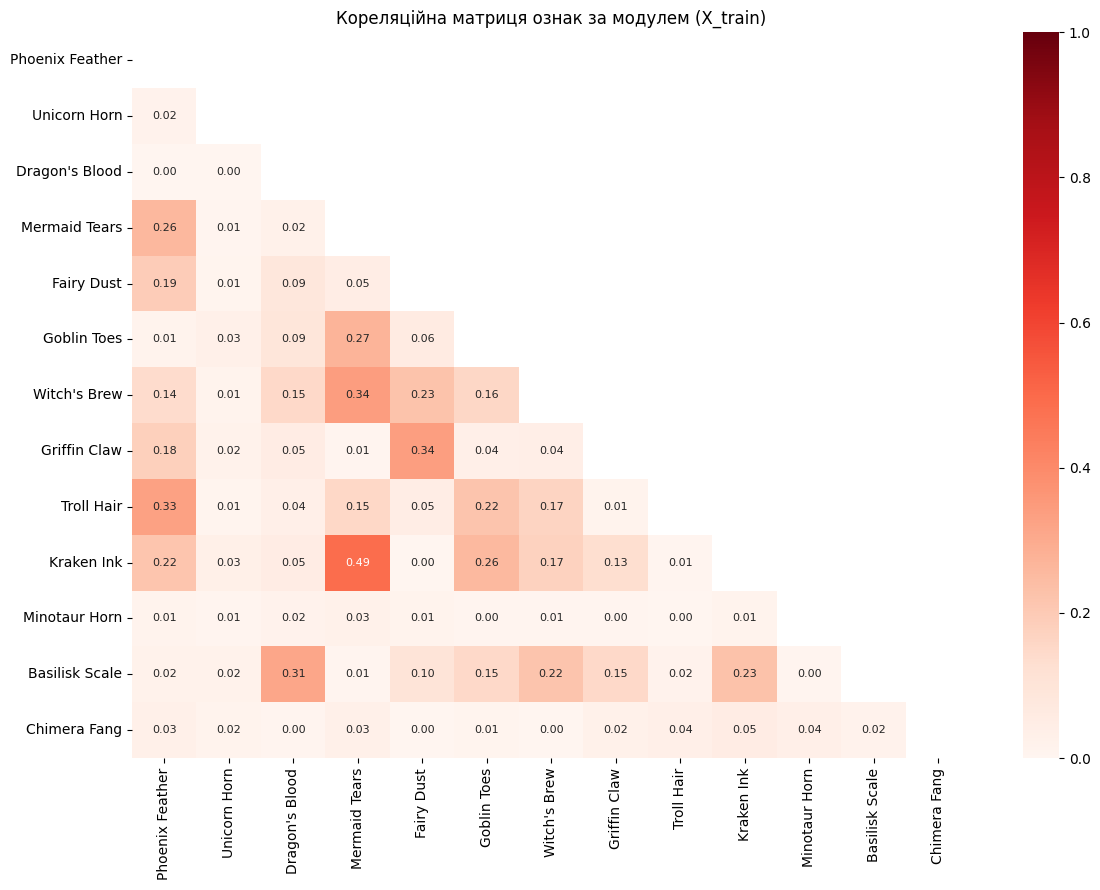

Топ-5 пар ознак за модулем кореляції:
Kraken Ink      Mermaid Tears      0.491
Witch's Brew    Mermaid Tears      0.343
Griffin Claw    Fairy Dust         0.339
Troll Hair      Phoenix Feather    0.330
Basilisk Scale  Dragon's Blood     0.313
dtype: float64


In [12]:
# Кореляційна матриця ознак за модулем
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1,
            annot_kws={'size': 8})
plt.title('Кореляційна матриця ознак за модулем (X_train)')
plt.tight_layout()
plt.show()

# Найбільш корельовані пари ознак
pairs = mtx.where(~mask).stack().sort_values(ascending=False)
print("Топ-5 пар ознак за модулем кореляції:")
print(pairs.head(5).round(3))

,Кореляція з Cured
Troll Hair,0.489
Witch's Brew,0.247
Goblin Toes,0.053
Chimera Fang,0.047
Basilisk Scale,-0.042
Kraken Ink,-0.027
Minotaur Horn,0.022
Phoenix Feather,0.021
Fairy Dust,0.014
Dragon's Blood,0.010


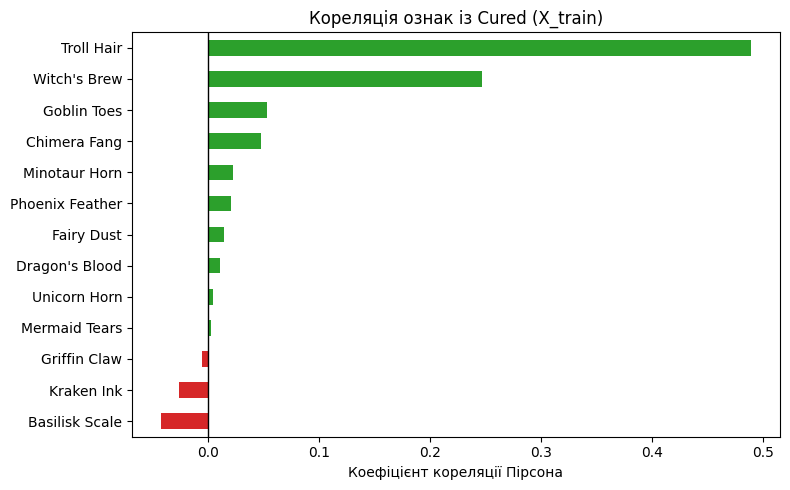

In [13]:
# Кореляція кожної ознаки з цільовою змінною Cured (лише train)
train_full = pd.concat([X_train, y_train], axis=1)
corr_target = train_full.corr()['Cured'].drop('Cured').sort_values(key=abs, ascending=False)
display(corr_target.round(3).to_frame('Кореляція з Cured'))

plt.figure(figsize=(8, 5))
corr_target.sort_values().plot(kind='barh', color=np.where(corr_target.sort_values() > 0, 'tab:green', 'tab:red'))
plt.axvline(0, color='black', linewidth=1)
plt.title('Кореляція ознак із Cured (X_train)')
plt.xlabel('Коефіцієнт кореляції Пірсона')
plt.tight_layout()
plt.show()

**Висновок про кореляції:**  
Сильних кореляцій між ознаками немає: найбільш корельовані пари — `Kraken Ink`–`Mermaid Tears` (0,49), `Witch's Brew`–`Mermaid Tears` (0,34), `Griffin Claw`–`Fairy Dust` (0,34) і `Troll Hair`–`Phoenix Feather` (0,33), отже мультиколінеарність не є проблемою. Найсильніший лінійний зв'язок із `Cured` має `Troll Hair` (0,49), помітний — `Witch's Brew` (0,25); решта ознак мають майже нульову кореляцію (|r| < 0,06). Низька лінійна кореляція не означає, що ознака непотрібна — вона може впливати на результат нелінійно або разом з іншими інгредієнтами, тому всі ознаки залишаємо.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # параметри — лише з train
X_test_scaled = scaler.transform(X_test)

print("Середні X_train_scaled:", np.round(X_train_scaled.mean(axis=0), 3)[:5], "...")
print("Std X_train_scaled:    ", np.round(X_train_scaled.std(axis=0), 3)[:5], "...")

Середні X_train_scaled: [ 0.  0.  0. -0. -0.] ...
Std X_train_scaled:     [1. 1. 1. 1. 1.] ...


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

Accuracy: 0.8932
F1-score: 0.8941

Classification report:
              precision    recall  f1-score   support

           0      0.888     0.896     0.892       231
           1      0.898     0.890     0.894       237

    accuracy                          0.893       468
   macro avg      0.893     0.893     0.893       468
weighted avg      0.893     0.893     0.893       468



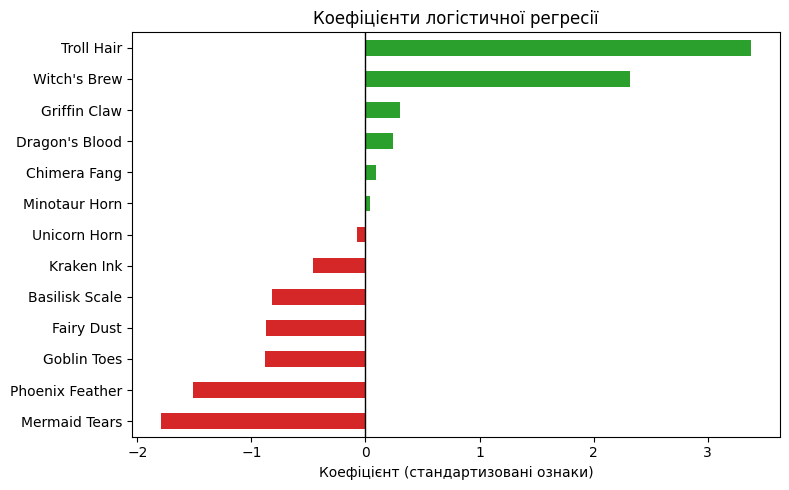

In [15]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3))

# Коефіцієнти моделі: вплив ознак (на стандартизованій шкалі)
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
coef.plot(kind='barh', color=np.where(coef > 0, 'tab:green', 'tab:red'))
plt.axvline(0, color='black', linewidth=1)
plt.title('Коефіцієнти логістичної регресії')
plt.xlabel('Коефіцієнт (стандартизовані ознаки)')
plt.tight_layout()
plt.show()

### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

[[207  24]
 [ 26 211]]


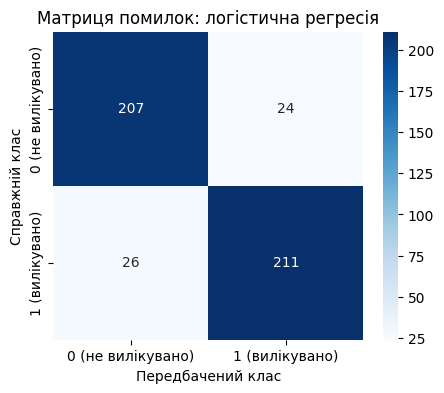

TN = 207, FP = 24, FN = 26, TP = 211


In [16]:
conf = confusion_matrix(y_test, y_pred)
print(conf)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0 (не вилікувано)', '1 (вилікувано)'],
            yticklabels=['0 (не вилікувано)', '1 (вилікувано)'])
plt.title('Матриця помилок: логістична регресія')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()

tn, fp, fn, tp = conf.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

In [17]:
results = pd.DataFrame({
    'Справжній клас': y_test.values,
    'Передбачений клас': y_pred,
}, index=y_test.index)
results['Збіг'] = np.where(results['Справжній клас'] == results['Передбачений клас'], 'так', 'ні')

sample10 = results.sample(10, random_state=42)
display(sample10)
print(f"Правильних прогнозів: {(sample10['Збіг'] == 'так').sum()} з 10")

,Справжній клас,Передбачений клас,Збіг
1133,0,1,ні
1018,0,0,так
1761,1,0,ні
564,1,1,так
1467,1,1,так
1927,0,0,так
408,1,1,так
2094,1,1,так
532,0,0,так
291,1,1,так


Правильних прогнозів: 8 з 10


**Висновок щодо якості логістичної регресії:**  
Базова логістична регресія досягла Accuracy = 0,893 і F1 = 0,894 на тестовій вибірці. За матрицею помилок модель зробила 24 хибнопозитивні помилки (принцесу «вилікувано», хоча насправді ні) і 26 хибнонегативних (лікування спрацювало, але модель цього не передбачила) — помилки розподілені майже рівномірно, precision і recall обох класів ≈ 0,89–0,90. На 10 випадкових тестових спостереженнях модель помилилась двічі (8 з 10 правильних). Однієї метрики Accuracy недостатньо: вона не показує, якого типу помилки переважають, а в задачі «врятувати принцесу» хибнопозитивний прогноз (думаємо, що зілля діє, а воно не діє) значно небезпечніший. Тому потрібно дивитися також на precision, recall, F1 та матрицю помилок.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
# Сітка для GridSearchCV (перебір усіх комбінацій)
param_grid = [
    {'C': [0.001, 0.01, 0.1, 1, 10, 100],
     'solver': ['lbfgs', 'newton-cg', 'liblinear', 'saga'],
     'max_iter': [100, 500, 1000]},
]

# Розподіли для RandomizedSearchCV (випадкова вибірка комбінацій)
from scipy.stats import loguniform
param_dist = {
    'C': loguniform(1e-3, 1e2),
    'solver': ['lbfgs', 'newton-cg', 'liblinear', 'saga'],
    'max_iter': [100, 300, 500, 1000],
}
print("Комбінацій у GridSearchCV:", 6 * 4 * 3)

Комбінацій у GridSearchCV: 72


In [19]:
grid = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("GridSearchCV — найкращі параметри:", grid.best_params_)
print(f"GridSearchCV — найкраща accuracy на CV: {grid.best_score_:.4f}")

GridSearchCV — найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
GridSearchCV — найкраща accuracy на CV: 0.8674


In [20]:
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=40, cv=3,
                                   scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)

best_random_params = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                      for k, v in random_search.best_params_.items()}
print("RandomizedSearchCV — найкращі параметри:", best_random_params)
print(f"RandomizedSearchCV — найкраща accuracy на CV: {random_search.best_score_:.4f}")

RandomizedSearchCV — найкращі параметри: {'C': 14.5282, 'max_iter': 300, 'solver': 'newton-cg'}
RandomizedSearchCV — найкраща accuracy на CV: 0.8674


In [21]:
# Обираємо модель із кращою accuracy на кросвалідації (тест не використовуємо для вибору)
if grid.best_score_ >= random_search.best_score_:
    best_lr, best_source = grid.best_estimator_, 'GridSearchCV'
else:
    best_lr, best_source = random_search.best_estimator_, 'RandomizedSearchCV'
print("Обрано модель з:", best_source, "|", best_lr)

y_pred_best = best_lr.predict(X_test_scaled)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred_best):.4f}  (базова: {accuracy_score(y_test, y_pred):.4f})")
print(f"F1-score: {f1_score(y_test, y_pred_best):.4f}  (базова: {f1_score(y_test, y_pred):.4f})")
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, digits=3))
print("Матриця помилок:\n", confusion_matrix(y_test, y_pred_best))

Обрано модель з: GridSearchCV | LogisticRegression(C=10)

Accuracy: 0.8932  (базова: 0.8932)
F1-score: 0.8941  (базова: 0.8941)

Classification report:
              precision    recall  f1-score   support

           0      0.888     0.896     0.892       231
           1      0.898     0.890     0.894       237

    accuracy                          0.893       468
   macro avg      0.893     0.893     0.893       468
weighted avg      0.893     0.893     0.893       468

Матриця помилок:
 [[207  24]
 [ 26 211]]


**Висновок про підбір параметрів:**  
GridSearchCV перебрав 72 комбінації і обрав `C=10, solver='lbfgs', max_iter=100`; RandomizedSearchCV з 40 випадковими комбінаціями знайшов близьке рішення `C≈14.5, solver='newton-cg', max_iter=300`. Обидва методи досягли однакової accuracy на кросвалідації — 0,867, тобто випадковий пошук отримав той самий результат за меншу кількість перевірок. Обидва методи обрали слабшу регуляризацію (більше `C`), ніж за замовчуванням (`C=1`), але на тестовій вибірці якість **не змінилася**: Accuracy = 0,893, F1 = 0,894, матриця помилок та сама. Отже, для цих даних логістична регресія вже працює на межі своїх можливостей: тип розв'язувача та кількість ітерацій не впливають на результат, а зміна `C` лише незначно змінює коефіцієнти. Подальшого покращення можна досягти лише моделлю, яка враховує нелінійні залежності.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

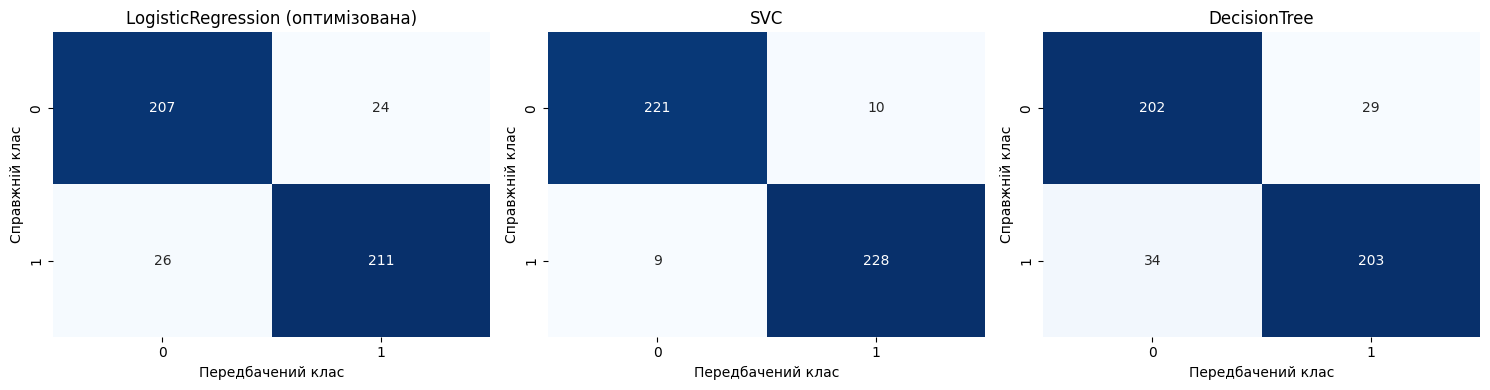

,Accuracy,F1-score
Модель,,
SVC,0.9594,0.9600
LogisticRegression (оптимізована),0.8932,0.8941
DecisionTree,0.8654,0.8657


Найкраща модель за F1-score: SVC


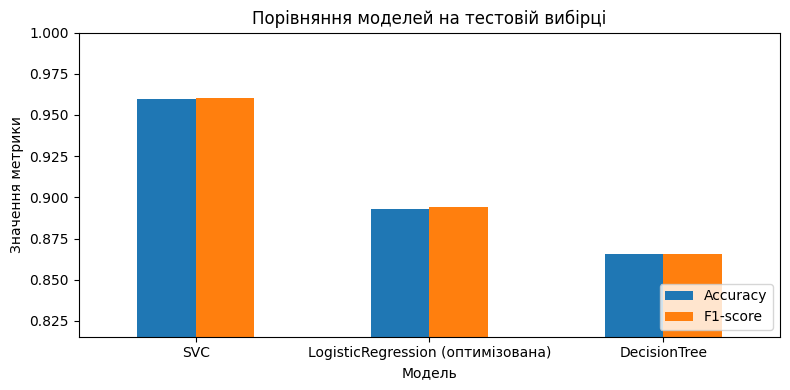

In [22]:
svc = SVC()
tree = DecisionTreeClassifier(random_state=42)

compare_models = {
    'LogisticRegression (оптимізована)': best_lr,
    'SVC': svc,
    'DecisionTree': tree,
}

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, clf) in zip(axes, compare_models.items()):
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    rows.append({'Модель': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'F1-score': f1_score(y_test, pred)})
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set(title=name, xlabel='Передбачений клас', ylabel='Справжній клас')
plt.tight_layout()
plt.show()

comparison = pd.DataFrame(rows).set_index('Модель').sort_values('F1-score', ascending=False)
display(comparison.round(4))

best_name = comparison['F1-score'].idxmax()
print(f"Найкраща модель за F1-score: {best_name}")

comparison.plot(kind='bar', figsize=(8, 4), rot=0, ylim=(comparison.min().min() - 0.05, 1))
plt.title('Порівняння моделей на тестовій вибірці')
plt.ylabel('Значення метрики')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Висновок щодо порівняння моделей.** Найкращою виявилась модель **SVC** (RBF-ядро): Accuracy = 0,959 і F1 = 0,960, що на 6,6 п. п. краще за логістичну регресію (0,893 / 0,894). Дерево рішень показало найнижчу якість (0,865 / 0,866): одиночне дерево без обмеження глибини перенавчається на тренувальних даних. Перевага SVC пояснюється тим, що RBF-ядро будує нелінійну межу між класами, а логістична регресія — лише лінійну; оскільки більшість інгредієнтів мають майже нульову лінійну кореляцію з `Cured`, але все ж впливають на результат, залежність у даних, імовірно, нелінійна.

### 13. Висновки до лабораторної роботи

1. **Особливості даних.** Датасет *Cure the Princess* містить 2 338 спостережень, 13 числових ознак-інгредієнтів і бінарну ціль `Cured`. Пропусків і дублікатів немає, ознаки мають схожі діапазони (1–45), але різні дисперсії, тому їх стандартизовано. Класи збалансовані (≈ 50,6 % / 49,4 % у train), тому Accuracy є коректною метрикою.

2. **Викиди та кореляції на навчальній вибірці.** За правилом 1,5·IQR викиди невеликі за кількістю (найбільше — 33 у `Witch's Brew`, загалом 5,3 % рядків) і лише верхні; вони правдоподібні, тому не видалялися. Сильної мультиколінеарності немає (максимум 0,49 для `Kraken Ink`–`Mermaid Tears`). З ціллю найсильніше пов'язані `Troll Hair` (0,49) та `Witch's Brew` (0,25), решта ознак мають майже нульову лінійну кореляцію.

3. **Базова логістична регресія.** Модель досягла Accuracy = 0,893 і F1 = 0,894 на тесті; помилки розподілені рівномірно (24 хибнопозитивні та 26 хибнонегативних).

4. **Підбір гіперпараметрів.** GridSearchCV (`C=10, lbfgs`) і RandomizedSearchCV (`C≈14.5, newton-cg`) дали однакову accuracy на CV (0,867), але метрики на тесті не покращилися — логістична регресія вже досягла межі якості для лінійної моделі.

5. **Найкраща модель.** Найкращою виявилась **SVC**: Accuracy = 0,959, F1 = 0,960 — значно краще за логістичну регресію (0,893) і дерево рішень (0,865). Її перевага пояснюється здатністю RBF-ядра будувати нелінійну межу між класами, тоді як дерево рішень без обмежень глибини перенавчається. Для практичного застосування слід обрати SVC.

